# Hotel Review Sentiment: what is the label hiding, and does a language model help?

**The question:** the legacy notebook takes 38,932 hotel reviews labelled **happy** or **not happy**, throws away the browser and device columns, cleans the text, fits a TF-IDF + logistic regression model and reports about 88% accuracy with a precision score computed with its arguments the wrong way round. *What do the dropped columns tell us? How much better can a careful bag-of-words model do? Can a language model (DistilBERT) used out of the box, or fine-tuned on a few thousand reviews, beat it? And what is left that no model gets right?* Everything is scored on the same held-out reviews.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the reviews
4. Hypotheses and why we chose each test
5. Looking at the metadata and the length
6. The split and the tools
7. The models
8. H3: how much do a better model and the metadata add?
9. H4: does a model trained on movie reviews work out of the box?
10. H5: how many labelled reviews does a fine-tuned DistilBERT need?
11. The scoreboard
12. What nobody gets right
13. Takeaways
14. Limitations

**Run it:** `uv run jupyter lab NLP/hotel-review-sentiment/hotel_review_sentiment.ipynb`, or *Run All* in any Jupyter. The data are the Kaggle "Hotel Review" files (a login is needed); put `train.csv` and `test.csv` into `data/` as `hotel_review_train.csv` and `hotel_review_test.csv`. DistilBERT (about 270 MB) downloads itself. It uses a GPU if present and takes about an hour on one.

## 1. 💡 The simple analogy

Imagine sorting a pile of **guest comment cards** into "happy" and "not happy".

- **The word-counting clerk** looks for the words that unhappy guests use ("dirty", "noisy", "rude"). He is fast and, with enough cards, very good.
- **The well-read clerk (DistilBERT)** has read millions of other texts. If you give him **movie reviews as his only training**, he understands "awful" and "wonderful", but a hotel guest is happy or not for other reasons ("the location was great but the room was tiny").
- **The cards also carry a stamp** (which browser or device the guest used). Nobody would expect a stamp to say anything about happiness, so the legacy notebook threw it away. We check whether it should have.
- **Some cards cannot be sorted** by anyone: the comment is glowing but the box says "not happy".

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the test share (20%), the maximum review length (256 word-pieces) and the training sizes keeps the notebook reproducible and avoids "magic numbers". The seeds are fixed and the GPU is set to deterministic mode.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import re
import string
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub.utils import logging as hub_logging
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import f1_score, precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FINETUNE_MODEL = "distilbert-base-uncased"
ZERO_SHOT_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
SEED = 365
TEST_SIZE = 0.2
MAX_LEN = 256
BATCH = 32
LEARNING_RATE = 5e-5
EPOCHS = 2
CURVE_SIZES = {500: 3, 2_000: 3, 8_000: 1}  # training size -> number of seeds
N_BOOTSTRAP = 1_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the reviews

*What:* the Kaggle "Hotel Review" training file: 38,932 reviews with a **happy / not happy** label, plus a **browser** and a **device** column. There is also a second file of 29,404 reviews with no labels, which we do not use. We look at class balance, duplicates, missing values, review length, and the browser names (eleven spellings of seven browsers: "IE", "Internet Explorer" and "InternetExplorer" are the same thing). *Why:* hidden duplicates leak between train and test, and inconsistent names split one group into several.

> **Problems in the legacy notebook this replaces:** it dropped the browser and device columns without looking at them; it computed `precision_score(predictions, y_test)` with the arguments **swapped** (true labels and predictions the wrong way round); it reported one number from one split, with no baseline and no confidence interval; and it printed a prediction for the unlabelled file as if that were a result.

In [2]:
reviews = pd.read_csv(DATA_DIR / "hotel_review_train.csv")
unlabelled = pd.read_csv(DATA_DIR / "hotel_review_test.csv")
BROWSER_FAMILY = {
    "Firefox": "Firefox",
    "Mozilla Firefox": "Firefox",
    "Mozilla": "Mozilla (unspecified)",
    "Google Chrome": "Chrome",
    "Chrome": "Chrome",
    "InternetExplorer": "Internet Explorer",
    "IE": "Internet Explorer",
    "Internet Explorer": "Internet Explorer",
    "Edge": "Edge",
    "Safari": "Safari",
    "Opera": "Opera",
}
reviews["browser"] = reviews["Browser_Used"].map(BROWSER_FAMILY)
reviews["happy"] = (reviews["Is_Response"] == "happy").astype(int)
reviews["words"] = reviews["Description"].str.split().str.len()
print(f"{len(reviews):,} labelled reviews (and {len(unlabelled):,} without labels, not used here)")
print(f"Happy: {reviews['happy'].mean():.1%}; not happy: {1 - reviews['happy'].mean():.1%}")
print(
    f"Missing values: {int(reviews.isna().sum().sum())}; duplicate reviews: "
    f"{int(reviews['Description'].duplicated().sum())}; duplicate user ids: "
    f"{int(reviews['User_ID'].duplicated().sum())}"
)
print(
    f"Browser labels: {reviews['Browser_Used'].nunique()} spellings -> "
    f"{reviews['browser'].nunique()} browsers; devices: "
    + ", ".join(f"{k} {v:,}" for k, v in reviews["Device_Used"].value_counts().items())
)
print(
    "Review length in words: median {:.0f}, 90th percentile {:.0f}, longest {}".format(
        reviews["words"].median(), reviews["words"].quantile(0.9), reviews["words"].max()
    )
)
print(f"Reviews longer than {MAX_LEN} words: {(reviews['words'] > MAX_LEN).mean():.1%}")

38,932 labelled reviews (and 29,404 without labels, not used here)
Happy: 68.1%; not happy: 31.9%
Missing values: 0; duplicate reviews: 0; duplicate user ids: 0
Browser labels: 11 spellings -> 7 browsers; devices: Desktop 15,026, Mobile 14,976, Tablet 8,930
Review length in words: median 123, 90th percentile 309, longest 2289
Reviews longer than 256 words: 15.4%


**How to read this:**

- **38,932 labelled reviews, 68.1% happy and 31.9% not happy.** A model that always says "happy" is right 68.1% of the time, so accuracy alone says little; we also use **AUC** and the F1 score for the "not happy" class.
- **A clean file:** no missing values, no duplicate reviews and no duplicate user ids, so a random split does not leak copies.
- **Browser names need cleaning:** 11 spellings become **7 browsers**. "Mozilla" on its own is ambiguous (every browser's identifier starts with it) so it keeps its own group.
- **Reviews are long:** median **123** words, 90th percentile **309**, longest 2,289; **15.4%** are longer than the 256 word-pieces DistilBERT will read, so for those it sees only the start.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Are the device and browser columns unrelated to happiness? | Unrelated | Related | Chi-square test, Cramér's V, Wilson intervals per group |
| H2 | Are unhappy reviews as long as happy ones? | Same length | Differ | Mann-Whitney U test, Cliff's δ |
| H3 | Does a better-tuned bag-of-words model, and then adding device and browser, beat the legacy model? | Same | Better | Exact McNemar test on the same test reviews; bootstrap interval for the AUC difference |
| H4 | Does a sentiment model trained only on movie reviews work on hotel reviews, without any training here? | As good as a model trained on hotel reviews | Differs | Exact McNemar test; AUC difference |
| H5 | Does a fine-tuned DistilBERT beat the trained TF-IDF, and how many labelled reviews does it need? | Same | Differs by training size | Learning curve (500, 2,000, 8,000 reviews; 3, 3 and 1 seeds); McNemar and AUC difference at 8,000 |

*Why these tests?* Every model is scored on the **same 7,787 test reviews**, so the exact **McNemar test**, which uses only the reviews where two models disagree, compares accuracy fairly. The **AUC** (the chance that a random happy review scores above a random unhappy one) needs no threshold, and a bootstrap that resamples test reviews gives its uncertainty. For H1 and H2 we use classic tests with effect sizes (Cramér's V and Cliff's δ), which say how big an effect is, not only whether it exists.

## 5. Looking at the metadata and the length

*What:* the share of happy reviews for each device and each (cleaned) browser with 95% Wilson intervals, a chi-square test and Cramér's V for each column, and the length of happy against unhappy reviews with a Mann-Whitney test and Cliff's δ (which runs from -1 to +1; 0 means no difference). *Why:* the dropped columns may hold a signal, and length is a free feature.

In [3]:
rows = []
for col in ("Device_Used", "browser"):
    table = pd.crosstab(reviews[col], reviews["happy"])
    chi2, p, _, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(f"{col}: chi-square p = {fmt_p(p)}, Cramer's V = {v:.3f}")
    for name, (neg, pos) in table.iterrows():
        low, high = proportion_confint(pos, pos + neg, method="wilson")
        rows.append(
            {
                "factor": col,
                "group": name,
                "n": pos + neg,
                "happy": pos / (pos + neg),
                "low": low,
                "high": high,
            }
        )
rates = pd.DataFrame(rows)
print(
    rates.assign(
        happy=lambda d: d["happy"].round(3),
        low=lambda d: d["low"].round(3),
        high=lambda d: d["high"].round(3),
    ).to_string(index=False)
)
happy_len = reviews.loc[reviews["happy"] == 1, "words"]
unhappy_len = reviews.loc[reviews["happy"] == 0, "words"]
mw = stats.mannwhitneyu(unhappy_len, happy_len)
delta = 2 * mw.statistic / (len(happy_len) * len(unhappy_len)) - 1
print(
    f"\nLength in words: not happy median {unhappy_len.median():.0f}, happy median "
    f"{happy_len.median():.0f}; Mann-Whitney p = {fmt_p(mw.pvalue)}, Cliff's delta = "
    f"{delta:+.2f} (positive: unhappy reviews are longer)"
)

Device_Used: chi-square p = 1.5e-84, Cramer's V = 0.100
browser: chi-square p = < 1e-300, Cramer's V = 0.352
     factor                 group     n  happy   low  high
Device_Used               Desktop 15026  0.705 0.698 0.712
Device_Used                Mobile 14976  0.708 0.701 0.715
Device_Used                Tablet  8930  0.596 0.586 0.606
    browser                Chrome  7129  0.861 0.853 0.869
    browser                  Edge  7134  0.451 0.440 0.463
    browser               Firefox 11695  0.589 0.580 0.598
    browser     Internet Explorer  9130  0.866 0.859 0.873
    browser Mozilla (unspecified)  3092  0.595 0.578 0.613
    browser                 Opera   362  0.666 0.616 0.712
    browser                Safari   390  0.728 0.682 0.770

Length in words: not happy median 151, happy median 111; Mann-Whitney p = < 1e-300, Cliff's delta = +0.23 (positive: unhappy reviews are longer)


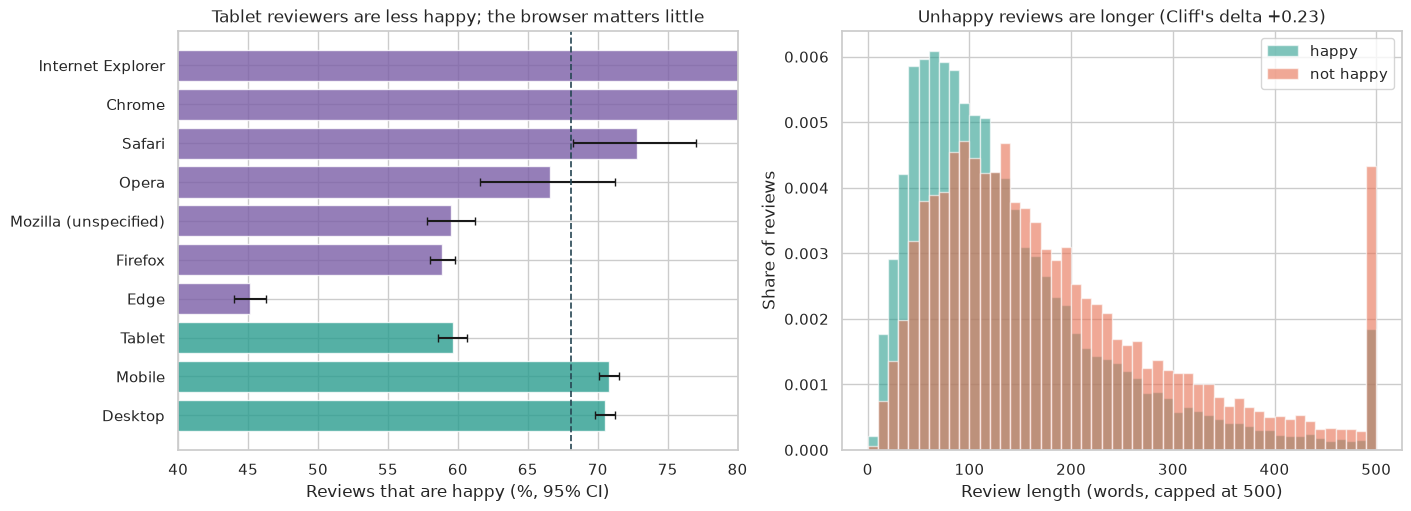

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
ordered = pd.concat(
    [
        rates[rates["factor"] == "Device_Used"],
        rates[rates["factor"] == "browser"].sort_values("happy"),
    ]
)
colors = [TEAL if f == "Device_Used" else PURPLE for f in ordered["factor"]]
y_pos = np.arange(len(ordered))
axes[0].barh(
    y_pos,
    ordered["happy"] * 100,
    color=colors,
    alpha=0.8,
    xerr=[(ordered["happy"] - ordered["low"]) * 100, (ordered["high"] - ordered["happy"]) * 100],
    capsize=3,
)
axes[0].axvline(reviews["happy"].mean() * 100, color=NAVY, ls="--", lw=1.2)
axes[0].set_yticks(y_pos, ordered["group"])
axes[0].set_xlim(40, 80)
axes[0].set_xlabel("Reviews that are happy (%, 95% CI)")
axes[0].set_title("Tablet reviewers are less happy; the browser matters little")
bins = np.linspace(0, 500, 51)
axes[1].hist(
    happy_len.clip(upper=500), bins=bins, alpha=0.6, color=TEAL, density=True, label="happy"
)
axes[1].hist(
    unhappy_len.clip(upper=500), bins=bins, alpha=0.6, color=ORANGE, density=True, label="not happy"
)
axes[1].set_xlabel("Review length (words, capped at 500)")
axes[1].set_ylabel("Share of reviews")
axes[1].set_title(f"Unhappy reviews are longer (Cliff's delta {delta:+.2f})")
axes[1].legend()
fig.savefig(OUT_DIR / "01_metadata_and_length.png", dpi=150)
plt.show()

**How to read this:**

- **The device matters:** **70.5%** of desktop and **70.8%** of mobile reviews are happy, but only **59.6%** of tablet reviews (CI 58.6% to 60.6%). The chi-square p-value is 1.5e-84, with Cramér's V = **0.10** (a small to moderate effect).
- **The browser matters far more:** **86.1%** of Chrome and **86.6%** of Internet Explorer reviews are happy, against **45.1%** for Edge (CI 44.0% to 46.3%), and 58.9% for Firefox. Cramér's V is **0.35**, a large effect (p below 1e-300). **We reject H₀ for both columns.**
- **Do not read this as cause:** there is no reason Edge users should be unhappier with a hotel. It is most likely an artefact of how this competition data were put together, which is exactly the kind of leak a model will happily exploit. The column is useful *in this file*, and it would not carry over to real reviews.
- **Unhappy reviews are longer:** median **151** words against **111** for happy ones (Mann-Whitney p below 1e-300), Cliff's δ = **+0.23**, a small to moderate effect: people write more when they complain. **We reject H₀.**

## 6. The split and the tools

*What:* a stratified random **80/20 split** (31,145 training and 7,787 test reviews), keeping the happy share the same in both. Because the file has no duplicates, a random split does not leak. We also define the tools used throughout: a bootstrap that gives a metric with a 95% interval by resampling test reviews, and an exact McNemar test. *Why:* one fixed test set, scored by every model, makes the comparisons paired and fair.

In [5]:
train, test = train_test_split(
    reviews, test_size=TEST_SIZE, stratify=reviews["happy"], random_state=SEED
)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
y_test = test["happy"].to_numpy()
print(
    f"Training reviews: {len(train):,}; test reviews: {len(test):,} "
    f"(happy {y_test.mean():.1%} in both)"
)
print(f"A model that always says 'happy' is right {y_test.mean():.1%} of the time")


def bootstrap(metric, truth: np.ndarray, *scores: np.ndarray) -> tuple[float, float, float]:
    """A metric with a 95% bootstrap interval that resamples test reviews.

    Args:
        metric: A function ``metric(truth, scores)`` returning a number.
        truth: True labels.
        *scores: One or two score arrays (predictions or probabilities).

    Returns:
        The metric, and the 2.5th and 97.5th percentiles over resamples.
    """
    values = []
    for _ in range(N_BOOTSTRAP):
        pick = rng.integers(0, len(truth), len(truth))
        values.append(metric(truth[pick], *[s[pick] for s in scores]))
    return metric(truth, *scores), *np.percentile(values, [2.5, 97.5])


def mcnemar_p(truth: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray) -> tuple[int, int, float]:
    """Exact McNemar test: reviews A gets right and B wrong, the reverse, and the p-value."""
    a, b = pred_a == truth, pred_b == truth
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum())
    mc = mcnemar([[int((a & b).sum()), only_a], [only_b, int((~a & ~b).sum())]], exact=True)
    return only_a, only_b, float(mc.pvalue)


def accuracy(truth: np.ndarray, pred: np.ndarray) -> float:
    """Share of correct predictions."""
    return float((truth == pred).mean())


probs = {}  # model name -> probability of "happy" for each test review

Training reviews: 31,145; test reviews: 7,787 (happy 68.1% in both)
A model that always says 'happy' is right 68.1% of the time


**How to read this:** 31,145 training and **7,787** test reviews, with **68.1%** happy in both. The baseline to beat is "always happy": 68.1% accuracy.

## 7. The models

*What:* five models on the same test reviews.

1. **Legacy TF-IDF:** the legacy cleaning (lower-case, remove brackets, punctuation and numbers), single words, default logistic regression.
2. **Tuned TF-IDF:** raw text with words and word pairs (1-2 grams), minimum 3 occurrences, sub-linear counts, and the regularisation strength chosen by 3-fold validation on the training reviews.
3. **Tuned TF-IDF + device and browser:** the same, with the device and the cleaned browser as extra columns.
4. **Zero-shot DistilBERT:** `distilbert-base-uncased-finetuned-sst-2-english`, trained on movie sentences, used as it comes (first 256 word-pieces).
5. **Fine-tuned DistilBERT:** `distilbert-base-uncased` fine-tuned on hotel reviews (2 passes, AdamW, learning rate 0.00005, batches of 32, first 256 word-pieces), on 500, 2,000 or 8,000 reviews.

All output a probability of "happy"; a review is called happy above 0.5.

In [6]:
def legacy_clean(text: str) -> str:
    """The legacy cleaning: lower-case, drop bracketed parts, punctuation and numbers."""
    text = text.lower()
    text = re.sub(r"\([^()]*\)", "", text)
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r"\w*\d\w*", "", text)
    return re.sub(r"\s+", " ", text).strip()


def make_tfidf(use_meta: bool = False, cv_choose_c: bool = True) -> Pipeline:
    """Word (1-2 words) TF-IDF + logistic regression, optionally with device and browser.

    Args:
        use_meta: Add one-hot device and browser columns next to the text.
        cv_choose_c: Choose the regularisation strength by 3-fold validation on the training data
            (otherwise use the default C = 1, as the legacy code did).

    Returns:
        An unfitted pipeline that takes a data frame with ``Description``, ``Device_Used`` and
        ``browser`` columns.
    """
    text = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, strip_accents="unicode")
    parts = [("text", text, "Description")]
    if use_meta:
        parts.append(("meta", OneHotEncoder(handle_unknown="ignore"), ["Device_Used", "browser"]))
    clf = (
        LogisticRegressionCV(
            Cs=[1, 4, 16, 64],
            cv=3,
            max_iter=2000,
            scoring="roc_auc",
            l1_ratios=(0.0,),
            use_legacy_attributes=False,
        )
        if cv_choose_c
        else LogisticRegression(max_iter=2000)
    )
    return Pipeline([("features", ColumnTransformer(parts)), ("clf", clf)])


def finetune(frame: pd.DataFrame, seed: int):
    """Fine-tunes DistilBERT to tell happy from not-happy reviews.

    Args:
        frame: Training reviews (``Description`` and ``happy`` columns).
        seed: Seed for the new classification layer and the batch order.

    Returns:
        The fine-tuned model in evaluation mode.
    """
    torch.manual_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(FINETUNE_MODEL, num_labels=2)
    model = model.to(DEVICE)
    ids, mask = encode(frame["Description"], FINETUNE_TOKENIZER)
    labels = torch.tensor(frame["happy"].to_numpy(), device=DEVICE)
    steps_per_epoch = int(np.ceil(len(frame) / BATCH))
    total = EPOCHS * steps_per_epoch
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total), total)
    for _ in range(EPOCHS):
        model.train()
        order = torch.randperm(len(frame), device=DEVICE)
        for start in range(0, len(frame), BATCH):
            pick = order[start : start + BATCH]
            out = model(input_ids=ids[pick], attention_mask=mask[pick], labels=labels[pick])
            optimizer.zero_grad()
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
    return model.eval()


@torch.no_grad()
def happy_probability(model, texts: pd.Series, tokenizer, batch: int = 128) -> np.ndarray:
    """Probability of 'happy' (class 1) for each review.

    Args:
        model: A sequence classifier whose class 1 is the positive class.
        texts: The reviews.
        tokenizer: The model's tokenizer.
        batch: Reviews per forward pass.

    Returns:
        Probabilities, shape (n,).
    """
    ids, mask = encode(texts, tokenizer)
    out = []
    for start in range(0, len(ids), batch):
        logits = model(
            input_ids=ids[start : start + batch], attention_mask=mask[start : start + batch]
        ).logits
        out.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(out)


def encode(texts: pd.Series, tokenizer) -> tuple[torch.Tensor, torch.Tensor]:
    """Turns reviews into padded word-piece ids and attention masks (first MAX_LEN pieces)."""
    e = tokenizer(
        list(texts), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt"
    )
    return e["input_ids"].to(DEVICE), e["attention_mask"].to(DEVICE)


FINETUNE_TOKENIZER = AutoTokenizer.from_pretrained(FINETUNE_MODEL)
ZERO_SHOT_TOKENIZER = AutoTokenizer.from_pretrained(ZERO_SHOT_MODEL)
print(f"Device: {DEVICE}; reviews are cut to the first {MAX_LEN} word-pieces")

Device: cuda; reviews are cut to the first 256 word-pieces


**How to read this:** the device is a GPU and the reviews are cut to the first 256 word-pieces for both DistilBERT models.

## 8. H3: how much do a better model and the metadata add?

*What:* fit the legacy TF-IDF model and replay its evaluation, including the precision score the legacy notebook computed with swapped arguments. Then fit the tuned TF-IDF model and the version with device and browser. We compare each with the one before using an exact McNemar test and a bootstrap interval for the AUC difference. *Why:* the legacy 88% needs a context, and the dropped columns have a price tag.

In [7]:
legacy_x_train = train["Description"].map(legacy_clean)
legacy_x_test = test["Description"].map(legacy_clean)
legacy = Pipeline([("vec", TfidfVectorizer()), ("clf", LogisticRegression(max_iter=2000))])
legacy.fit(legacy_x_train, train["happy"])
probs["legacy TF-IDF (cleaned text, default settings)"] = legacy.predict_proba(legacy_x_test)[:, 1]
legacy_pred = (probs["legacy TF-IDF (cleaned text, default settings)"] > 0.5).astype(int)
print(f"Legacy replica: accuracy {accuracy(y_test, legacy_pred):.4f}")
print(
    "The legacy notebook called precision_score(predictions, y_test), with the arguments "
    "the wrong way round:"
)
print(
    f"  legacy 'precision' (arguments swapped): "
    f"{precision_score(legacy_pred, y_test, average='weighted'):.4f}"
)
real = precision_score(y_test, legacy_pred, average="weighted")
print(f"  real weighted precision:                {real:.4f}")
print(
    f"  real precision for the 'not happy' class: "
    f"{precision_score(y_test, legacy_pred, pos_label=0):.4f}; recall "
    f"{(legacy_pred[y_test == 0] == 0).mean():.4f}"
)

Legacy replica: accuracy 0.8849
The legacy notebook called precision_score(predictions, y_test), with the arguments the wrong way round:
  legacy 'precision' (arguments swapped): 0.8918
  real weighted precision:                0.8838
  real precision for the 'not happy' class: 0.8624; recall 0.7603


In [8]:
tuned = make_tfidf().fit(train, train["happy"])
probs["TF-IDF, tuned (word 1-2 grams)"] = tuned.predict_proba(test)[:, 1]
chosen_c = tuned.named_steps["clf"].C_
with_meta = make_tfidf(use_meta=True).fit(train, train["happy"])
probs["TF-IDF + device and browser"] = with_meta.predict_proba(test)[:, 1]
print(
    f"Regularisation chosen by 3-fold validation: C = {chosen_c} (without metadata), "
    f"C = {with_meta.named_steps['clf'].C_} (with metadata)"
)

Regularisation chosen by 3-fold validation: C = 4.0 (without metadata), C = 16.0 (with metadata)


**How to read this:**

- **The legacy model replays at 88.49% accuracy** (AUC 0.943, F1 for "not happy" 0.808). Its "precision" was computed as `precision_score(predictions, y_test)`, with the arguments the wrong way round: it printed **0.8918**, while the real weighted precision is **0.8838**, and the precision for the "not happy" class is **0.8624** with a recall of only **0.7603**: it misses a quarter of the unhappy guests.
- **Better tuning helps a little:** the tuned TF-IDF model reaches **89.69%** (AUC **0.951**), right where the legacy model is wrong on 199 reviews and wrong where it is right on 106 (exact McNemar p = 1e-7); the AUC gain is **+0.0077** (95% CI +0.0058 to +0.0096). **We reject H₀.**
- **The dropped columns were worth keeping (here):** adding device and browser gives **90.47%** accuracy and AUC **0.960** (+0.0086, CI +0.0064 to +0.0109), right where the text-only model is wrong on 241 reviews and wrong where it is right on 180 (p = 0.0034). **We reject H₀.** Given the browser effect in section 5, treat this as a lesson about leaks rather than a feature to deploy.
- The regularisation chosen by validation is C = 4 without and C = 16 with the metadata.

## 9. H4: does a model trained on movie reviews work out of the box?

*What:* run the SST-2 DistilBERT (trained to say whether a *movie* sentence is positive or negative) on the hotel test reviews, with no training on hotels, and compare it with the trained TF-IDF model. *Why:* a free pretrained model is the cheapest option; the question is how much the change of topic costs.

In [9]:
zero_model = AutoModelForSequenceClassification.from_pretrained(ZERO_SHOT_MODEL).to(DEVICE).eval()
probs["zero-shot DistilBERT (trained on movie reviews)"] = happy_probability(
    zero_model, test["Description"], ZERO_SHOT_TOKENIZER
)
print("Zero-shot model: labels", zero_model.config.id2label)
del zero_model
torch.cuda.empty_cache()

Zero-shot model: labels {0: 'NEGATIVE', 1: 'POSITIVE'}


**How to read this:** the zero-shot model labels `NEGATIVE` and `POSITIVE` (class 1 = positive = happy). Its results are in the scoreboard below: **85.49%** accuracy, AUC **0.915** and F1 for "not happy" **0.771**. Against the trained TF-IDF it is right alone on **322** reviews and wrong alone on **649** (exact McNemar p = 4e-26), with an AUC **0.036 lower** (95% CI -0.0416 to -0.0309). **We reject H₀.** It is a respectable start for zero labelled hotel reviews, but a bag-of-words model trained on the hotel data beats it clearly.

## 10. H5: how many labelled reviews does a fine-tuned DistilBERT need?

*What:* a **learning curve**. For training sizes of **500, 2,000 and 8,000** reviews (3, 3 and 1 random subsets), fine-tune DistilBERT and fit the tuned TF-IDF model on the same reviews, and score both on the same 7,787 test reviews. The TF-IDF model trained on all 31,145 reviews is the reference. *Why:* the real-world question is how much labelling you need before the more expensive model pays off.

In [10]:
curve_rows, finetuned = [], {}
for size, n_seeds in CURVE_SIZES.items():
    for seed in range(n_seeds):
        subset = train.sample(size, random_state=SEED + seed)
        small = make_tfidf().fit(subset, subset["happy"])
        p_tfidf = small.predict_proba(test)[:, 1]
        model = finetune(subset, seed=seed)
        p_bert = happy_probability(model, test["Description"], FINETUNE_TOKENIZER)
        del model
        torch.cuda.empty_cache()
        for name, p in [("TF-IDF", p_tfidf), ("DistilBERT fine-tuned", p_bert)]:
            curve_rows.append(
                {
                    "model": name,
                    "n": size,
                    "seed": seed,
                    "auc": roc_auc_score(y_test, p),
                    "accuracy": accuracy(y_test, (p > 0.5).astype(int)),
                }
            )
        finetuned[(size, seed)] = p_bert
        print(
            f"  {size} reviews, seed {seed}: TF-IDF AUC {curve_rows[-2]['auc']:.4f}, "
            f"DistilBERT AUC {curve_rows[-1]['auc']:.4f}"
        )
curve = pd.DataFrame(curve_rows)
full = {
    "model": "TF-IDF",
    "n": len(train),
    "seed": 0,
    "auc": roc_auc_score(y_test, probs["TF-IDF, tuned (word 1-2 grams)"]),
    "accuracy": accuracy(y_test, (probs["TF-IDF, tuned (word 1-2 grams)"] > 0.5).astype(int)),
}
curve = pd.concat([curve, pd.DataFrame([full])], ignore_index=True)
probs[f"DistilBERT fine-tuned on {max(CURVE_SIZES):,} reviews"] = finetuned[(max(CURVE_SIZES), 0)]
summary = curve.groupby(["model", "n"])[["auc", "accuracy"]].mean().round(4)
print()
print(summary.unstack(0).to_string())

  500 reviews, seed 0: TF-IDF AUC 0.8968, DistilBERT AUC 0.9149


  500 reviews, seed 1: TF-IDF AUC 0.8987, DistilBERT AUC 0.9129


  500 reviews, seed 2: TF-IDF AUC 0.8874, DistilBERT AUC 0.7552


  2000 reviews, seed 0: TF-IDF AUC 0.9264, DistilBERT AUC 0.9403


  2000 reviews, seed 1: TF-IDF AUC 0.9279, DistilBERT AUC 0.9359


  2000 reviews, seed 2: TF-IDF AUC 0.9267, DistilBERT AUC 0.9385


  8000 reviews, seed 0: TF-IDF AUC 0.9410, DistilBERT AUC 0.9505

                        auc                      accuracy        
model DistilBERT fine-tuned  TF-IDF DistilBERT fine-tuned  TF-IDF
n                                                                
500                  0.8610  0.8943                0.7891  0.8066
2000                 0.9382  0.9270                0.8752  0.8622
8000                 0.9505  0.9410                0.8924  0.8831
31145                   NaN  0.9510                   NaN  0.8969


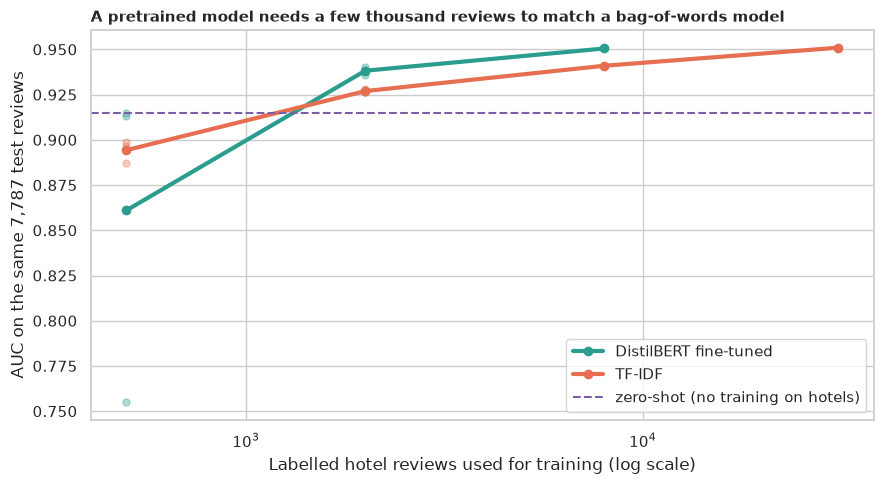

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in [("DistilBERT fine-tuned", TEAL), ("TF-IDF", ORANGE)]:
    sub = curve[curve["model"] == name]
    ax.scatter(sub["n"], sub["auc"], color=color, alpha=0.35, s=25)
    mean = sub.groupby("n")["auc"].mean()
    ax.plot(mean.index, mean.values, color=color, lw=3, marker="o", label=name)
zero_auc = roc_auc_score(y_test, probs["zero-shot DistilBERT (trained on movie reviews)"])
ax.axhline(zero_auc, color=PURPLE, ls="--", lw=1.5, label="zero-shot (no training on hotels)")
ax.set_xscale("log")
ax.set_xlabel("Labelled hotel reviews used for training (log scale)")
ax.set_ylabel("AUC on the same 7,787 test reviews")
ax.set_title(
    "A pretrained model needs a few thousand reviews to match a bag-of-words model",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_learning_curve.png", dpi=150)
plt.show()

**How to read this:**

- **With 500 reviews the two are close, and DistilBERT is unstable:** the mean AUC is **0.861** for DistilBERT against **0.894** for TF-IDF, but the mean hides a failed run: seeds 0 and 1 of DistilBERT reach **0.915** and **0.913** (above TF-IDF's 0.897 and 0.899) while seed 2 reaches only **0.755**. A fine-tuned model on 500 reviews can sometimes fail to train.
- **With 2,000 reviews DistilBERT is ahead:** AUC **0.938** against **0.927** (accuracy 87.5% against 86.2%), in all 3 seeds (0.940, 0.936, 0.939 against 0.926, 0.928, 0.927).
- **With 8,000 reviews:** **0.9505** against **0.941** for TF-IDF trained on the same reviews, and **equal to the TF-IDF trained on all 31,145 reviews (0.951)**: against that reference, accuracy is 89.2% against 89.7%, McNemar p = 0.19, and an AUC difference of **-0.0005** (95% CI -0.0040 to +0.0030). The fine-tuned model matches the full-data bag-of-words model with about a quarter of the labels. **We cannot reject H₀ at the full-data reference:** they tie.
- **There is no knockout:** DistilBERT needs a few thousand labelled reviews just to reach what a bag of words achieves with 31,000.

## 11. The scoreboard

*What:* every model on the same 7,787 test reviews: accuracy and AUC with 95% bootstrap intervals, and F1 for the "not happy" class (the one we most want to find). *Why:* a single table puts the whole story side by side.

In [12]:
rows = []
for name, p in probs.items():
    pred = (p > 0.5).astype(int)
    acc = bootstrap(accuracy, y_test, pred)
    auc = bootstrap(roc_auc_score, y_test, p)
    rows.append(
        {
            "model": name,
            "accuracy": acc[0],
            "acc_low": acc[1],
            "acc_high": acc[2],
            "auc": auc[0],
            "auc_low": auc[1],
            "auc_high": auc[2],
            "F1 'not happy'": f1_score(y_test, pred, pos_label=0),
        }
    )
board = pd.DataFrame(rows).set_index("model")
print(board.round(4).to_string())
names = list(probs)
legacy_name, tuned_name, meta_name, zero_name, bert_name = (
    names[0],
    names[1],
    names[2],
    names[3],
    names[4],
)
for a, b, label in [
    (tuned_name, legacy_name, "tuned TF-IDF vs legacy TF-IDF"),
    (meta_name, tuned_name, "adding device and browser"),
    (zero_name, tuned_name, "zero-shot vs trained TF-IDF"),
    (bert_name, tuned_name, "fine-tuned DistilBERT vs trained TF-IDF"),
]:
    only_a, only_b, p = mcnemar_p(
        y_test, (probs[a] > 0.5).astype(int), (probs[b] > 0.5).astype(int)
    )
    diff = bootstrap(
        lambda t, x, z: roc_auc_score(t, x) - roc_auc_score(t, z), y_test, probs[a], probs[b]
    )
    print(
        f"{label}: right-only {only_a} vs {only_b} (exact McNemar p = {fmt_p(p)}); "
        f"AUC difference {diff[0]:+.4f} (95% CI {diff[1]:+.4f} to {diff[2]:+.4f})"
    )

                                                 accuracy  acc_low  acc_high     auc  auc_low  auc_high  F1 'not happy'
model                                                                                                                  
legacy TF-IDF (cleaned text, default settings)     0.8849   0.8775    0.8920  0.9433   0.9380    0.9485          0.8081
TF-IDF, tuned (word 1-2 grams)                     0.8969   0.8898    0.9041  0.9510   0.9457    0.9560          0.8285
TF-IDF + device and browser                        0.9047   0.8975    0.9111  0.9595   0.9551    0.9637          0.8447
zero-shot DistilBERT (trained on movie reviews)    0.8549   0.8474    0.8627  0.9150   0.9084    0.9213          0.7714
DistilBERT fine-tuned on 8,000 reviews             0.8924   0.8858    0.8991  0.9505   0.9457    0.9551          0.8266


tuned TF-IDF vs legacy TF-IDF: right-only 199 vs 106 (exact McNemar p = 1.1e-07); AUC difference +0.0077 (95% CI +0.0058 to +0.0096)


adding device and browser: right-only 241 vs 180 (exact McNemar p = 3.4e-03); AUC difference +0.0086 (95% CI +0.0064 to +0.0109)


zero-shot vs trained TF-IDF: right-only 322 vs 649 (exact McNemar p = 4.4e-26); AUC difference -0.0360 (95% CI -0.0416 to -0.0309)


fine-tuned DistilBERT vs trained TF-IDF: right-only 313 vs 348 (exact McNemar p = 1.9e-01); AUC difference -0.0005 (95% CI -0.0040 to +0.0030)


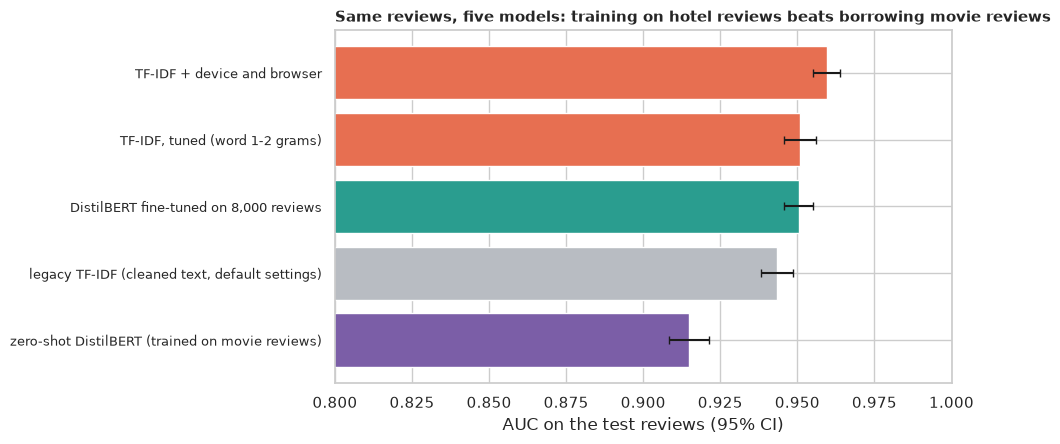

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.6))
order = board.sort_values("auc")
palette = {"legacy": GREY, "TF-IDF": ORANGE, "zero-shot": PURPLE, "DistilBERT": TEAL}
bar_colors = [next(c for k, c in palette.items() if n.startswith(k)) for n in order.index]
ax.barh(
    range(len(order)),
    order["auc"],
    color=bar_colors,
    xerr=[order["auc"] - order["auc_low"], order["auc_high"] - order["auc"]],
    capsize=3,
)
ax.set_yticks(range(len(order)), order.index, fontsize=9)
ax.set_xlim(0.8, 1.0)
ax.set_xlabel("AUC on the test reviews (95% CI)")
ax.set_title(
    "Same reviews, five models: training on hotel reviews beats borrowing movie reviews",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_model_comparison.png", dpi=150)
plt.show()

**How to read this:**

| Model | Accuracy | AUC | F1 "not happy" |
|---|---|---|---|
| Legacy TF-IDF | 88.5% | 0.943 | 0.808 |
| Tuned TF-IDF | 89.7% | 0.951 | 0.829 |
| Tuned TF-IDF + device and browser | **90.5%** | **0.960** | **0.845** |
| Zero-shot DistilBERT (movie reviews) | 85.5% | 0.915 | 0.771 |
| DistilBERT fine-tuned on 8,000 reviews | 89.2% | 0.951 | 0.827 |

- **The leak wins:** the model with the device and browser columns is best on every measure, ahead by 0.8 points of accuracy.
- **Fine-tuned DistilBERT ties tuned TF-IDF** (89.2% against 89.7%, AUC 0.9505 against 0.951; the intervals overlap).
- **The intervals matter:** each accuracy interval is about ±0.7 points wide. The legacy and tuned TF-IDF intervals just touch, but the paired McNemar test in section 8 separates them; fine-tuned DistilBERT and tuned TF-IDF are not separated (p = 0.19).

In [14]:
best = probs[bert_name]
ref = probs[tuned_name]
wrong = np.flatnonzero(((best > 0.5) != y_test) & ((ref > 0.5) != y_test))
print(
    f"Reviews both the fine-tuned DistilBERT and the tuned TF-IDF get wrong: {len(wrong)} "
    f"of {len(y_test):,} ({len(wrong) / len(y_test):.1%})"
)
confident = wrong[np.argsort(-np.abs(best[wrong] - 0.5))[:4]]
for i in confident:
    label = "happy" if y_test[i] else "not happy"
    print(
        f"  true {label}; DistilBERT P(happy) {best[i]:.2f}, TF-IDF {ref[i]:.2f}: "
        f"{test['Description'].iloc[i][:230]!r}"
    )

Reviews both the fine-tuned DistilBERT and the tuned TF-IDF get wrong: 490 of 7,787 (6.3%)
  true not happy; DistilBERT P(happy) 0.99, TF-IDF 0.99: 'my husband and i stayed here for - nights on our recent trip to nyc. the location was perfect! the staff was very friendly and helpful! also, it was nice to have a lounge in the lobby in the evenings so we could grab a drink or tw'
  true happy; DistilBERT P(happy) 0.01, TF-IDF 0.16: "The price and location is good considering it's in New York City, however, the room and bathroom were ridiculously small, barely any room for two suitcases, and one adult alone in the bathroom was very claustrophobic. Customer ser"
  true happy; DistilBERT P(happy) 0.01, TF-IDF 0.10: "The check in took forever, the names were misspelled and we had problems checking in. if not for tyhe reservation numbers it would have been a disaster and the front desk was less then helpful in solving any problems. He didn't se"
  true happy; DistilBERT P(happy) 0.01, TF-IDF 

**How to read this:**

- **6.3% of the test reviews** (490 of 7,787) are wrong for **both** the fine-tuned DistilBERT and the tuned TF-IDF, and several are wrong with high confidence.
- **They look like mixed reviews or label noise:** a "not happy" card that reads "the location was perfect! the staff was very friendly and helpful!" (both models say 0.99 happy), and "happy" cards that describe "ridiculously small" rooms, "check in took forever" and "noisy room, drafty windows, outdated decor".
- **That sets a ceiling:** if the labels were produced by a rule that the review text does not fully contain (a rating threshold, a browser quirk), no text model can get all of these right. About 6% of the data is out of reach for text alone.

## 12. 🎯 Takeaways

1. **The legacy 88% was a fair number with a wrong precision:** accuracy 88.49%, but the "precision" it printed (0.8918) came from swapped arguments (real 0.8838), and the model missed 24% of the unhappy guests (recall 0.7603 for that class).
2. **Better tuning gives a small, real gain:** 89.69% accuracy and AUC 0.951 (+0.0077, p = 1e-7).
3. **The dropped columns held a large leak:** 86% of Chrome and Internet Explorer reviews are happy against 45% for Edge (Cramér's V = 0.35); adding them lifts accuracy to 90.47%. It is a trap, not a feature.
4. **A pretrained model without training is not enough:** the movie-review model reaches 85.5% accuracy and AUC 0.915, clearly behind a bag of words trained on hotels (0.951).
5. **A fine-tuned DistilBERT ties a bag of words with about a quarter of the labels:** AUC 0.9505 with 8,000 reviews against 0.951 with 31,145; with 500 reviews it can fail to train.
6. **About 6% of reviews are wrong for every model,** often with a mismatch between the text and the label.

## 13. ⚠️ Limitations

- **One split, one test set.** Intervals describe the test reviews, not a different draw of training data; the bootstrap resamples test reviews only.
- **The browser effect is not causal** and probably comes from how the data were made, so the "metadata wins" result would not generalise to other review data.
- **Reviews are cut at 256 word-pieces,** which affects 15.4% of the reviews; a longer limit could help DistilBERT.
- **The learning curve has few seeds** (3, 3 and 1), and the 500-review DistilBERT runs show large run-to-run variation (one run reached only AUC 0.755).
- **DistilBERT settings were not tuned** (2 passes, one learning rate); neither was the TF-IDF model beyond its regularisation.
- **The labels are not verified:** the "happy" label may come from a rating rule, and some reviews contradict their label.
- **The unlabelled file was not used,** so the legacy "predictions on unseen reviews" cannot be checked.
- **Hotel reviews from one platform and period.** The vocabulary of other sites, other languages or other eras would differ.